In [1]:
import numpy as np
from tensorflow import keras 
import matplotlib.pyplot as plt 

In [2]:
data = np.load('cifar-10-python.npz')

In [3]:
data

NpzFile 'cifar-10-python.npz' with keys: x_test, x_train, y_train, y_test

In [4]:
x_train , y_train = data['x_train'] , data['y_train']

In [5]:
x_test , y_test = data['x_test'] , data['y_test']

In [6]:
x_train.shape

(50000, 32, 32, 3)

In [7]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

In [8]:
print(x_train.dtype)
print(x_train.min())
print(x_train.max())
print(x_train[0].shape)

float32
0.0
1.0
(32, 32, 3)


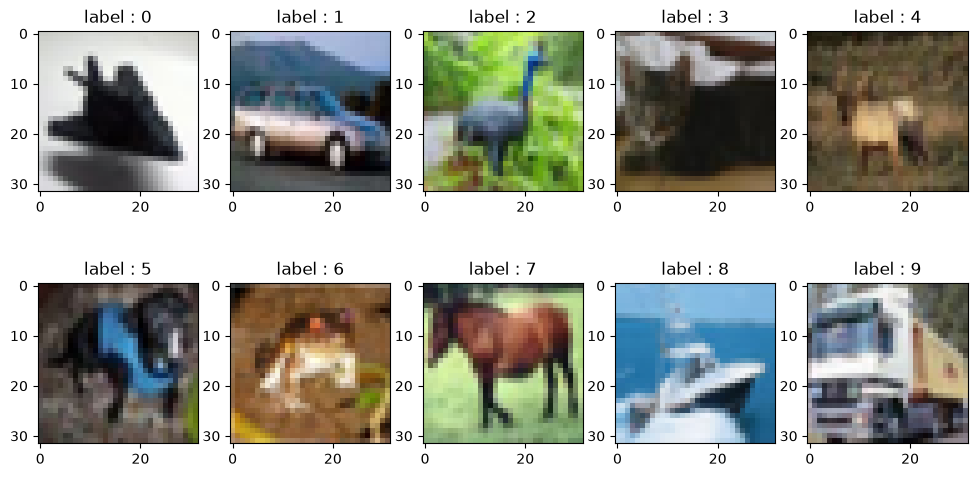

In [12]:
plt.figure(figsize=(12 , 6))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]
    plt.subplot(2 , 5 , i + 1)
    plt.imshow(x_train[index])
    plt.title(f"label : {i}")


In [13]:
class_names = ["airplane" , "automobile" , "bird" , "cat" , "deer" , "dog" , "frog" , "horse" , "ship" , "truck"]

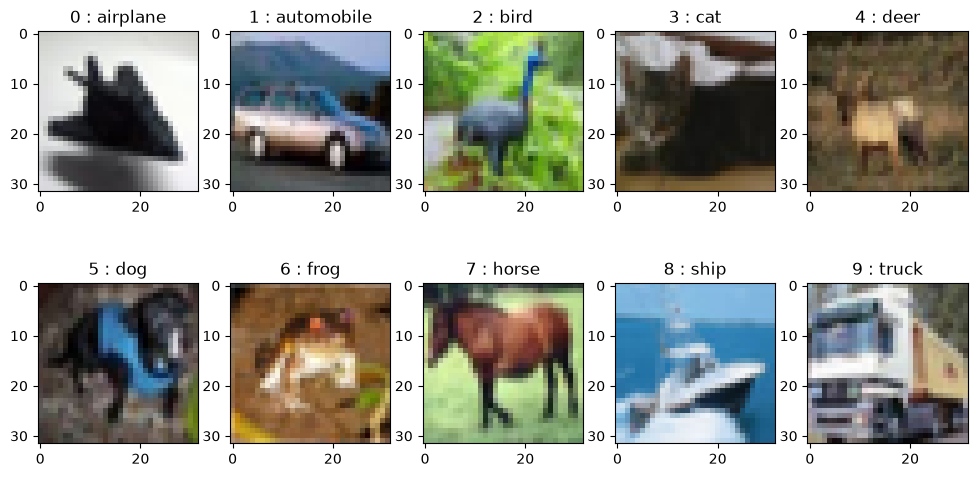

In [14]:
plt.figure(figsize=(12 , 6))

for i in range(10):
    index = np.where(y_train.flatten() == i)[0][0]
    plt.subplot(2 , 5 , i + 1)
    plt.imshow(x_train[index])
    plt.title(f"{i} : {class_names[i]}")


In [16]:
model = keras.Sequential([
    keras.Input(shape=(32 , 32 , 3)),
    keras.layers.Conv2D(32 , (3 , 3) , activation='relu'),
    keras.layers.MaxPooling2D((2 , 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64 , activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(10 , activation="softmax")
])

model.summary()
#fnn
# architecture 
# model = keras.Sequential([
#     keras.Input(shape=(32, 32, 3)),
#     keras.layers.Flatten(),
#     keras.layers.Dense(512, activation="relu"),
#     keras.layers.Dense(256, activation="relu"),
#     keras.layers.Dense(128, activation="relu"),
#     keras.layers.Dense(10, activation="softmax")
# ])
# model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)                    │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 7200)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │         460,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 462,410 (1.76 MB)

 Trainable params: 462,410 (1.76 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [18]:
es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train , y_train , 
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[es]
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.3720 - loss: 1.7024 - val_accuracy: 0.5061 - val_loss: 1.4136
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.4794 - loss: 1.4276 - val_accuracy: 0.5426 - val_loss: 1.2878
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5096 - loss: 1.3433 - val_accuracy: 0.5664 - val_loss: 1.2335
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5343 - loss: 1.2797 - val_accuracy: 0.5688 - val_loss: 1.2367
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.5527 - loss: 1.2321 - val_accuracy: 0.5839 - val_loss: 1.1934
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5653 - loss: 1.1907 - val_accuracy: 0.5798 - val_loss: 1.2273
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5796 - loss: 1.1507 - val_accuracy: 0.5979 - val_loss: 1.1612
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5890 - loss: 1.1196 - 

In [19]:
loss , acc = model.evaluate(x_test , y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6132 - loss: 1.1076


In [20]:
print(f"test accuracy : {acc * 100}")

test accuracy : 61.320000886917114


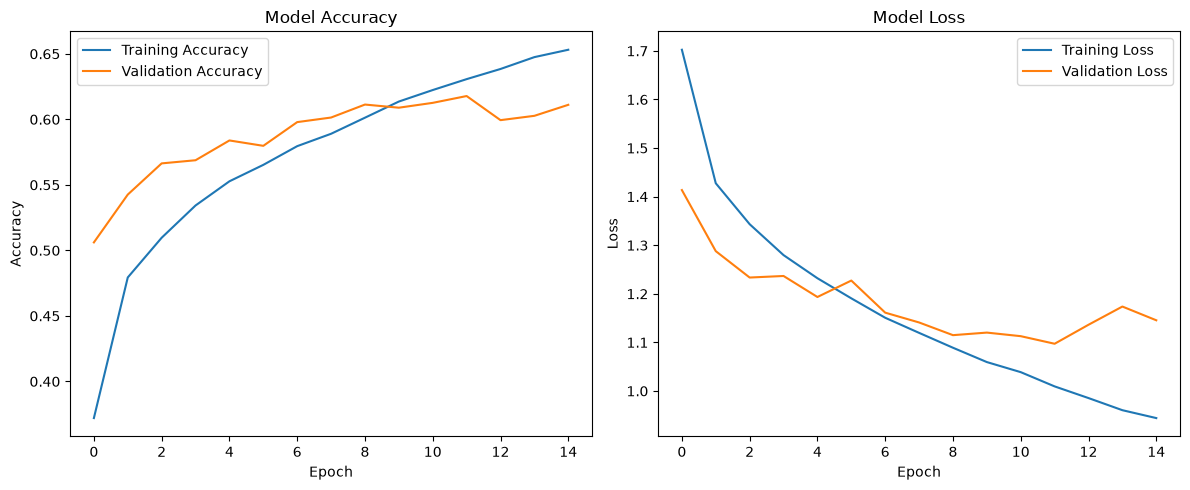

In [21]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
index = 12

prediction = model.predict(x_test[index:index+1])
predicted_class = np.argmax(prediction[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


Predicted class: dog
Actual class: dog


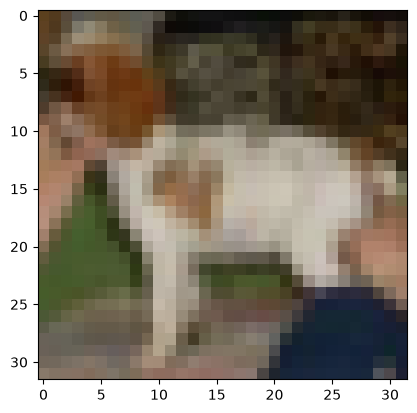

In [25]:
print("Predicted class:", class_names[predicted_class])
print("Actual class:", class_names[int(y_test[index].squeeze())])
plt.imshow(x_test[index])